# TP5 · Ejercicio 2c: un Pokémon nuevo más nítido, generando cerca de los datos
**Pregunta guía.** El ejercicio 2b mostró que el VAE convolucional dibuja nítido cerca de los códigos que vio y borroso lejos de ellos, y que muestrear de $\mathcal{N}(0,I)$ cae casi siempre lejos. ¿Se puede usar eso para generar una muestra nueva con contorno y ojos, sin reentrenar y sin dejar de ser una muestra del autoencoder?

**Qué se hace.** Con el **mismo modelo** del 2b (64×64, $\beta=1$, $d=64$, cargado de `results/`) se decodifican mezclas del código de un Pokémon con los de sus vecinos latentes. No hay entrenamiento nuevo ni librerías nuevas: sólo se elige de otra manera el punto $z$ que se decodifica. Corre en CPU en un par de minutos.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
import sys, copy, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
RAIZ = Path.cwd()
EJ2 = next(p for p in (RAIZ, RAIZ.parent.parent / "Ejercicio_2" / "codigo") if (p / "experimentos.py").exists())
EJ2B = next(p for p in (RAIZ, RAIZ.parent.parent / "Ejercicio_2b" / "codigo") if (p / "deep_conv.py").exists())
sys.path[:0] = [str(EJ2B), str(EJ2)]            # se reutilizan el código, los datos y el modelo ya entrenado; nada se modifica
from deep_conv import cargar_conv
from experimentos import *
from graficos import *
cfg64 = copy.deepcopy(cargar_config()); cfg64["ej2_pokemon"]["lado"] = 64
Q = datos_pokemon(cfg64); nombres, S64, n_orig = Q["nombres"], Q["shape"], len(Q["tr"])
vG, _ = cargar_conv(EJ2B / "results" / "ej2b_L64_b1_a4_s0_final.npz")     # VAE convolucional 64x64 del ejercicio 2b
def mosaico(filas, noms, formas, tam=1.0):
    """Como graficos.fila_comparada, pero cada fila puede tener su resolución."""
    n = len(filas[0]); fig, axs = plt.subplots(len(filas), n, figsize=(n * tam, len(filas) * tam * 1.08), squeeze=False)
    for r, (f, nom, sh) in enumerate(zip(filas, noms, formas)):
        for k in range(n):
            axs[r, k].imshow(np.clip(np.asarray(f[k]).reshape(sh), 0, 1)); axs[r, k].set_xticks([]); axs[r, k].set_yticks([])
            for s_ in axs[r, k].spines.values(): s_.set_visible(False)
        axs[r, 0].set_ylabel(nom, rotation=0, ha="right", va="center", fontsize=9)
    return fig
Xo = Q["Xtr"][:n_orig]; mu, lv = vG.encode(Xo)                             # códigos de los 728 Pokémon de entrenamiento
d2 = ((mu[:, None] - mu[None]) ** 2).sum(2); np.fill_diagonal(d2, np.inf)
med = np.median(dist_vecino(Q["Xte"], Q["Xtr"]))                           # distancia típica de un Pokémon real no visto a su vecino
GV = vG.decode(np.random.default_rng(3).standard_normal((2000, vG.latent)))   # muestras del prior, como referencia
print("Pokémon de entrenamiento:", n_orig, "| latente:", vG.latent, "| umbral de copia:", round(0.5 * med, 1))

Pokémon de entrenamiento: 728 | latente: 64 | umbral de copia: 11.1


## 1. La idea y el compromiso nitidez–copia
El ejercicio 2b deja una regla: **el decodificador dibuja nítido cerca de los códigos que vio y borroso lejos**. Muestrear de $\mathcal{N}(0,I)$ cae casi siempre lejos. En lugar del prior se puede muestrear de la zona donde están los datos: se toma un Pokémon $A$ y sus 3 vecinos latentes, y se decodifica una mezcla $z=w_A\,\mu_A+\sum_j w_j\,\mu_{B_j}$ con pesos al azar. Sigue siendo una muestra nueva del decodificador del VAE, sin reentrenar nada.

Hay un compromiso que conviene medir antes de elegir: cuanto más peso tiene $A$, más nítida es la figura y más se parece a $A$. **Nitidez** = módulo medio del gradiente de la imagen sobre la figura (los contornos y los ojos de un sprite son saltos bruscos entre píxeles vecinos).

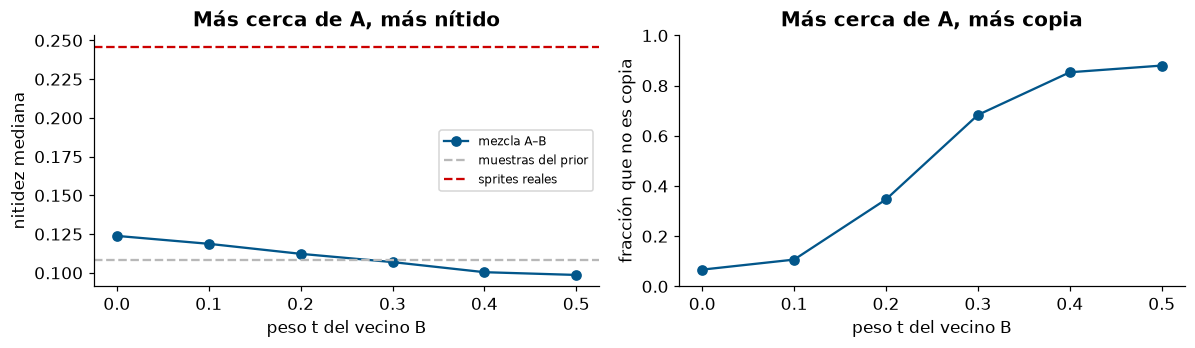

nitidez mediana: sprites reales 0.246 | reconstrucción de entrenamiento (t=0) 0.124 | punto medio (t=0,5) 0.099 | prior 0.108


In [2]:
def nitidez(X):
    """Módulo medio del gradiente de la imagen (diferencia entre píxeles vecinos), medido sólo sobre la figura."""
    I = X.reshape(-1, *S64); g = np.zeros(I.shape[:3])
    g[:, :, :-1] += np.abs(np.diff(I, axis=2)).mean(3); g[:, :-1, :] += np.abs(np.diff(I, axis=1)).mean(3)
    m_ = I.min(3) < 0.9
    return np.array([g[i][m_[i]].mean() if m_[i].sum() > 20 else 0.0 for i in range(len(I))])
umbral = 0.5 * med
vec3 = np.argsort(d2, 1)[:, :3]                                     # los 3 vecinos latentes de cada Pokémon
rng = np.random.default_rng(0); im = rng.choice(n_orig, 300, replace=False); ts = [0, .1, .2, .3, .4, .5]
curva = []
for t in ts:                                                         # z = (1-t)·μ_A + t·μ_B, con B el vecino más cercano
    G_ = vG.decode((1 - t) * mu[im] + t * mu[vec3[im, 0]]); d_ = dist_vecino(G_, Q["Xtr"])
    curva.append((np.median(nitidez(G_)), np.median(d_), (d_ > umbral).mean()))
curva = np.array(curva); nit_real, nit_prior = np.median(nitidez(Xo)), np.median(nitidez(GV))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3))
axs[0].plot(ts, curva[:, 0], "o-", color=AZUL, label="mezcla A–B"); axs[0].axhline(nit_prior, color=GRIS, ls="--", label="muestras del prior"); axs[0].axhline(nit_real, color=ROJO, ls="--", label="sprites reales")
axs[0].set_xlabel("peso t del vecino B"); axs[0].set_ylabel("nitidez mediana"); axs[0].set_title("Más cerca de A, más nítido"); axs[0].legend(fontsize=8)
axs[1].plot(ts, curva[:, 2], "o-", color=AZUL); axs[1].set_xlabel("peso t del vecino B"); axs[1].set_ylabel("fracción que no es copia"); axs[1].set_ylim(0, 1); axs[1].set_title("Más cerca de A, más copia")
plt.tight_layout(); plt.show()
print(f"nitidez mediana: sprites reales {nit_real:.3f} | reconstrucción de entrenamiento (t=0) {curva[0, 0]:.3f} | punto medio (t=0,5) {curva[-1, 0]:.3f} | prior {nit_prior:.3f}")

## 2. Candidatos: las mezclas más nítidas que no son copia

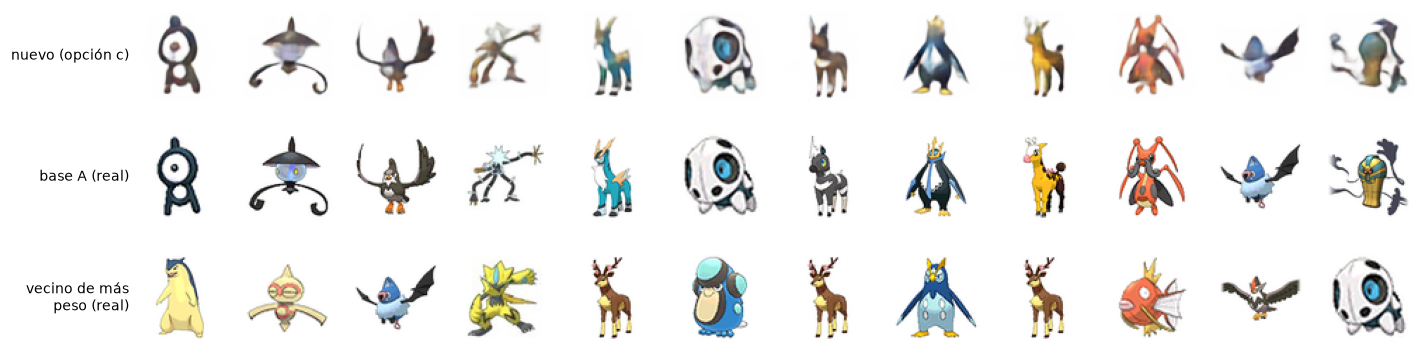

2022 de 3000 mezclas no son copias (umbral 11.1) | nitidez mediana de esas 0.108 | de las 12 mostradas 0.203 (prior 0.108, reales 0.246)
base, peso de A, distancia al dato más cercano: [('unown', 0.69, 11.9), ('lampent', 0.71, 14.2), ('staravia', 0.72, 14.3), ('xurkitree', 0.68, 12.1), ('cobalion', 0.68, 11.9), ('aron', 0.71, 11.8), ('blitzle', 0.56, 13.4), ('empoleon', 0.73, 12.2), ('girafarig', 0.54, 13.5), ('kricketune', 0.73, 12.4), ('swoobat', 0.65, 14.3), ('cofagrigus', 0.64, 14.7)]


In [3]:
N = 3000                                                             # candidatos: A con peso entre 0,5 y 0,75 y el resto repartido entre sus 3 vecinos
a_ = rng.choice(n_orig, N); wA = rng.uniform(0.5, 0.75, N); w = rng.dirichlet(np.ones(3) * 0.6, N) * (1 - wA)[:, None]
Gm = vG.decode(wA[:, None] * mu[a_] + (w[:, :, None] * mu[vec3[a_]]).sum(1))
dm, nm = dist_vecino(Gm, Q["Xtr"]), nitidez(Gm)
okc = np.where(dm > umbral)[0]                                       # se descartan las casi copias
top, usados = [], set()
for i in okc[np.argsort(-nm[okc])]:                                  # las más nítidas, un candidato por Pokémon base
    if a_[i] not in usados: top.append(i); usados.add(a_[i])
    if len(top) == 12: break
b1 = [vec3[a_[i], np.argsort(-w[i])[0]] for i in top]
mosaico([Gm[top], Xo[a_[top]], Xo[b1]], ["nuevo (opción c)", "base A (real)", "vecino de más\npeso (real)"], [S64] * 3, tam=1.25); plt.show()
print(f"{len(okc)} de {N} mezclas no son copias (umbral {umbral:.1f}) | nitidez mediana de esas {np.median(nm[okc]):.3f} | de las 12 mostradas {np.median(nm[top]):.3f} (prior {nit_prior:.3f}, reales {nit_real:.3f})")
print("base, peso de A, distancia al dato más cercano:", [(nombres[Q["tr"][a_[i]]], round(float(wA[i]), 2), round(float(dm[i]), 1)) for i in top])

## 3. El Pokémon nuevo elegido

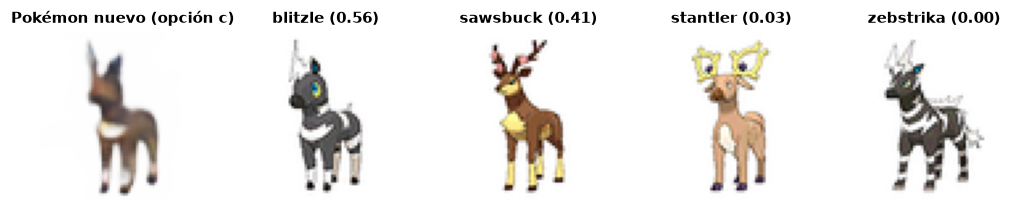

en píxeles: dato más cercano a 13.4 (umbral de copia 11.1; un Pokémon real no visto, mediana 22.1)
nitidez 0.201 (muestras del prior, mediana 0.108; sprites reales, mediana 0.246)


In [4]:
ELEGIDA = 6                                                          # elegida a ojo entre las 12 de arriba (igual que en el ejercicio 2)
ic_ = top[ELEGIDA]
padres = [a_[ic_]] + [vec3[a_[ic_], j] for j in np.argsort(-w[ic_])]
pesos = [wA[ic_]] + sorted(w[ic_], reverse=True)
fig = mostrar_imagenes(np.array([Gm[ic_]] + [Xo[j] for j in padres]), S64,
                       ["Pokémon nuevo (opción c)"] + [f"{nombres[Q['tr'][j]]} ({p:.2f})" for j, p in zip(padres, pesos)], ncols=5, tam=2.3, ax_title_size=10)
plt.show()
print(f"en píxeles: dato más cercano a {dm[ic_]:.1f} (umbral de copia {umbral:.1f}; un Pokémon real no visto, mediana {med:.1f})")
print(f"nitidez {nm[ic_]:.3f} (muestras del prior, mediana {nit_prior:.3f}; sprites reales, mediana {nit_real:.3f})")

## 4. Lectura y límites
**Lectura.**
- **El compromiso existe y se puede elegir el punto.** Con $t=0$ (reconstruir $A$) casi todo es copia; con $t=0{,}3$ ya dos tercios de las mezclas superan el umbral de copia, y la nitidez cae poco. Por eso los candidatos usan un peso de $A$ entre 0,5 y 0,75.
- **Las figuras elegidas así tienen contorno, extremidades y, en varios casos, ojos.** Son las muestras más nítidas del trabajo: su nitidez es del orden de la de un sprite real y casi el doble que la de una muestra del prior (ver las salidas de arriba). Ninguna es copia según el mismo umbral que se usó en todo el ejercicio 2.
- **La elegida**, a ojo entre las 12, es un cuadrúpedo marrón de patas claras y hocico oscuro: tiene el cuerpo de Blitzle y el pelaje de Sawsbuck, y no es ninguno de los dos. Es de las que menos peso le dan a su base (0,56).

**Qué hay que decir con honestidad.**
- No son criaturas inventadas desde cero: cada una es **una base reconocible deformada hacia sus vecinos**. Es un Pokémon nuevo en el sentido de la consigna (no está en el conjunto y se juzga que pertenece), no una especie original.
- **El techo de nitidez lo pone el decodificador:** incluso reconstruyendo un sprite de entrenamiento ($t=0$) la nitidez mediana es la mitad de la real. Elegir "las más nítidas" además favorece figuras oscuras y de mucho contraste.
- La selección mira 3000 candidatos y se queda con 12: es una búsqueda guiada, no una muestra típica. La muestra típica de esta zona es la del gráfico de arriba.